# Una esfera en un plano

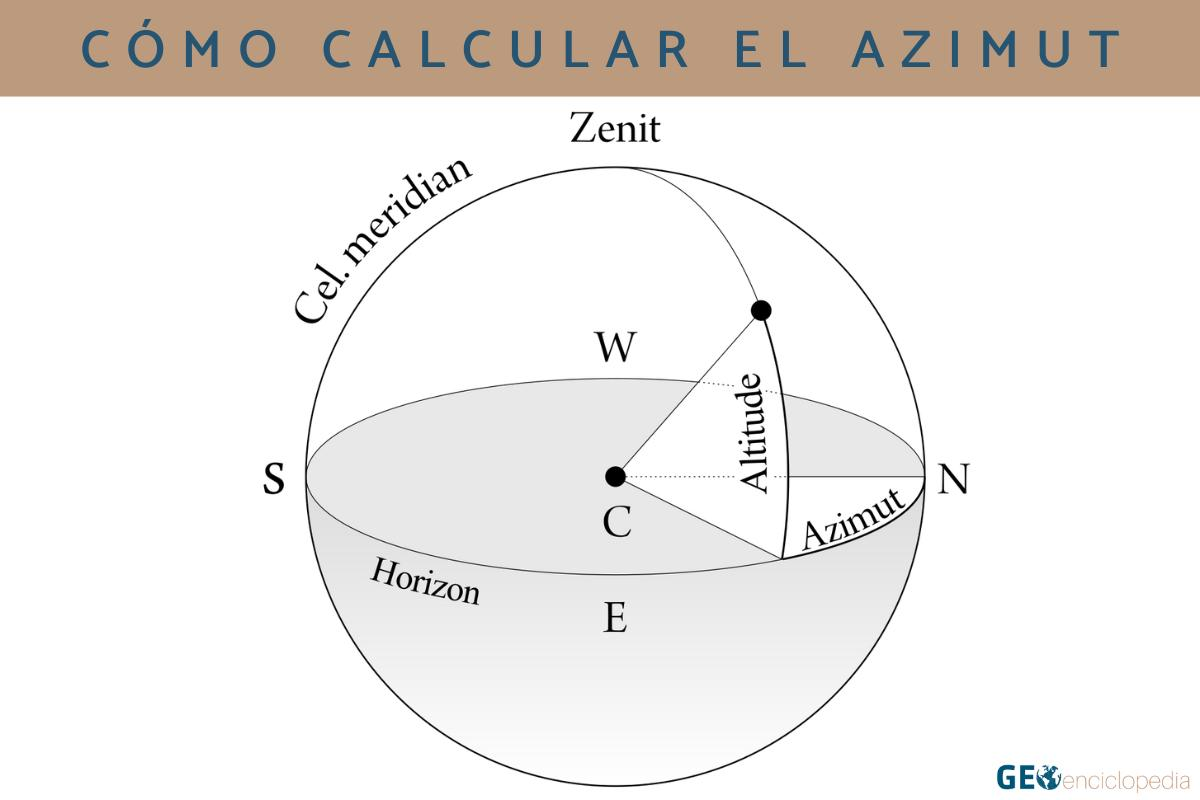

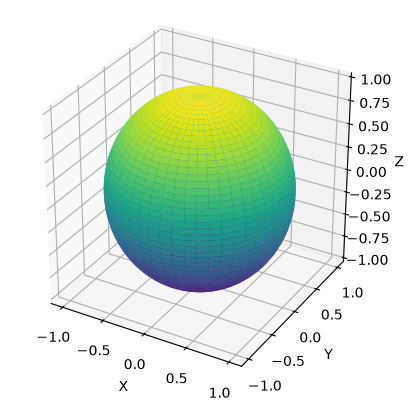

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la esfera
r = 1
#np.pi = π -> Y hacemos una lista de 0 a 2π, osea una vuelta completa
u = np.linspace(0, 2 * np.pi, 100)  # ángulo azimutal
v = np.linspace(0, np.pi, 100)      # ángulo polar

#Convertimos los angulos u y z en coordenadas x,y,z usando trigonometria
# np.outer(a, b) multiplica cada elemento de a con cada elemento de b y arma una tabla, como una tabla de multiplicar.
x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))



fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis') #Hace la superficie usando matrices


# Relacion de aspecto
ax.set_box_aspect((1, 1, 1))  

#Grilla
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()


# Sacamos el plano porque se ve feo

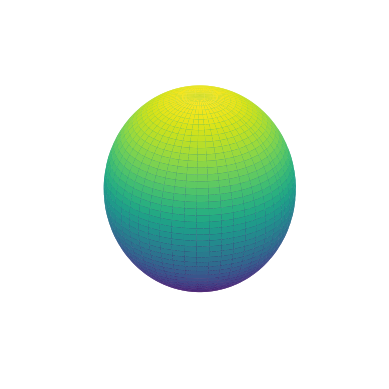

In [ ]:


r = 10
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)

x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis')

ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()  # quita grilla, ejes, paneles y etiquetas
plt.show()

# Probamos distintos colores


In [ ]:
ax.plot_surface(x, y, z, cmap='plasma')   
ax.plot_surface(x, y, z, cmap='ocean')    
ax.plot_surface(x, y, z, cmap='coolwarm') 
ax.plot_surface(x, y, z, cmap='viridis')

# Agregamos una elipse que en el futuro seria una orbita de satelite

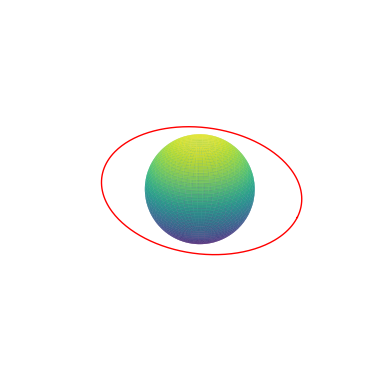

In [ ]:


# Esfera
r = 1
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

# Elipse
resolucion_elipse = 300
a, b = 2.0, 1.3          # semiejes mayor y menor
t = np.linspace(0, 2 * np.pi, resolucion_elipse)
ex = a * np.cos(t)
ey = b * np.sin(t)
ez = np.zeros_like(t) #como np.zeros(300)

# Inclinación de la elipse (rotación alrededor del eje X)
theta = np.radians(30)
ey_rot = ey * np.cos(theta) - ez * np.sin(theta)
ez_rot = ey * np.sin(theta) + ez * np.cos(theta)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ex, ey_rot, ez_rot, color='red', linewidth=1)

ax.set_box_aspect((1, 1, 1))

# Encuadre de la "camara"
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)


ax.set_axis_off()
plt.show()

# Le agregamos una esfera en la elipse, lo que vendria siendo un satelite 

In [26]:


def esfera(cx, cy, cz, r, n=60):
    u = np.linspace(0, 2 * np.pi, n)
    v = np.linspace(0, np.pi, n)
    x = cx + r * np.outer(np.cos(u), np.sin(v))
    y = cy + r * np.outer(np.sin(u), np.sin(v))
    z = cz + r * np.outer(np.ones_like(u), np.cos(v))
    return x, y, z


#cx, cy, cz: las coordenadas del centro de la esfera.
#r: el radio.
#n=60: cuántos puntos usar en cada ángulo, que tan suave se ve.

In [ ]:
# Elipse (órbita)
a, b = 2.0, 1.3
θ = np.radians(30)

def punto_orbita(t):
    ex = a * np.cos(t)
    ey = b * np.sin(t)
    ez = 0 * t
    # rotación alrededor del eje X
    ey_rot = ey * np.cos(θ) - ez * np.sin(θ)
    ez_rot = ey * np.sin(θ) + ez * np.cos(θ)
    return ex, ey_rot, ez_rot



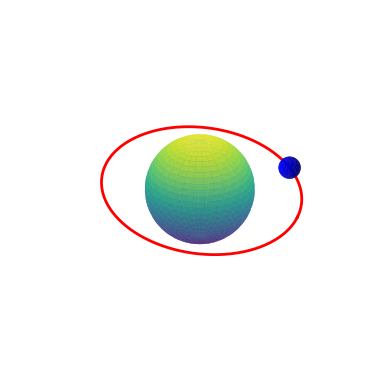

In [28]:

t = np.linspace(0, 2 * np.pi, 300)
ox, oy, oz = punto_orbita(t) # t es una lista: toda la órbita

# Posición de la pelotita sobre la órbita
t0 = np.radians(45)
px, py, pz = punto_orbita(t0)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Esfera grande (central)
x, y, z = esfera(0, 0, 0, 1)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)

# Órbita
ax.plot(ox, oy, oz, color='red', linewidth=2)

# Pelotita orbitando
x2, y2, z2 = esfera(px, py, pz, 0.2)
ax.plot_surface(x2, y2, z2, color='blue')

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
plt.show()

# Lo animamos para ver como quedaria

In [ ]:
#Dibuja el satélite en la posición de la órbita que le indiques 
# con t0, y antes borra el que dibujó la vez anterior. 
# La animación se arma llamándola muchas veces con valores de t0 distintos.

def dibujar_pelota(t0):
    if pelota[0] is not None:
        pelota[0].remove()
    px, py, pz = punto_orbita(t0)
    x2, y2, z2 = esfera(px, py, pz, 0.2)
    pelota[0] = ax.plot_surface(x2, y2, z2, color='green')


#Cada vez que se llama a dibujar_pelota(t0):

#borra la pelota vieja
#calcula la posición nueva
#dibuja la pelota en esa posición
#se acuerda de ella para borrarla después    

In [ ]:
#convierte el número de cuadro en un ángulo y se lo pasa a dibujar_pelota.
def actualizar(frame):
    dibujar_pelota(2 * np.pi * frame / 120)

In [ ]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Elementos fijos
x, y, z = esfera(0, 0, 0, 1, n=60)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ox, oy, oz, color='red', linewidth=2)



#--------------------------------
ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
#--------------------------------



# Pelotita: se dibuja desde el principio
pelota = [None]
#Es una lista con un solo elemento, que al principio es None (nada).
#  Ahí se guarda la esfera naranja que está dibujada en ese momento. 
# Usás una lista, y no una variable suelta, por una cuestión de Python: 
# dentro de una función no podés reasignar una variable de afuera (sin global),
#  pero sí podés modificar el contenido de una lista. Es un truco común.



dibujar_pelota(0)   # posición inicial, así se ve aunque no corra la animación



ani = FuncAnimation(fig, actualizar, frames=120, interval=30, blit=False)

# Blitting es una técnica de optimización para animaciones:
#  en vez de redibujar la figura completa en cada cuadro, 
# matplotlib redibuja solo lo que cambió y deja el resto como estaba



plt.close() # Sin esta linea se generan 2 "imagenes", una foto estatica y la animacion
HTML(ani.to_jshtml())


# Convierte tu animación en un bloque de HTML con JavaScript. Para eso matplotlib:

#Ejecuta tu función actualizar para cada uno de los 120 cuadros.
#Guarda cada cuadro como una imagen.
#Mete todas las imágenes dentro de una página HTML, junto con un pequeño reproductor en JavaScript.

